# MLP with RBF-KAN as activation function: MNIST Dataset

## Import

In [1]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
import numpy as np
from mlp_rbf_kan.models import MLP_RBFKAN, MLP, KAN, RBF_KAN, train_classification
from mlp_rbf_kan.eval.tools import *
from mlp_rbf_kan.eval.experiments import *

## MNIST Dataset

In [2]:
print("Download MNIST...")
train_data = datasets.MNIST(root='./data', train=True, download=True)
test_data  = datasets.MNIST(root='./data', train=False, download=True)

X_train_raw = train_data.data.numpy().astype(np.float32)
y_train_raw = train_data.targets.numpy().astype(np.int64)
X_test_raw  = test_data.data.numpy().astype(np.float32)
y_test_raw  = test_data.targets.numpy().astype(np.int64)

X_train_flat = X_train_raw.reshape(-1, 784) / 255.0
X_test_flat  = X_test_raw.reshape(-1, 784) / 255.0

X_train_t = torch.tensor(X_train_flat, dtype=torch.float32)
y_train_t = torch.tensor(y_train_raw, dtype=torch.long)
X_test_t  = torch.tensor(X_test_flat, dtype=torch.float32)
y_test_t  = torch.tensor(y_test_raw, dtype=torch.long)

train_dataset = TensorDataset(X_train_t, y_train_t)
test_dataset  = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=64)

print(f"MNIST dataset ready!")
print(f"Train set: {X_train_t.shape[0]} images")
print(f"Test set:  {X_test_t.shape[0]} images")
print(f"Input dimension (pixel): {X_train_t.shape[1]}")

Download MNIST...
MNIST dataset ready!
Train set: 60000 images
Test set:  10000 images
Input dimension (pixel): 784


## Training

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

input_dim = 784 
hidden_dim = 32 
output_dim = 10 
centers = 8 # or Knots
domain = (-3, 3)
shared_basis = True

# Models
mlp = MLP(input_dim, hidden_dim, output_dim)
kan = KAN(width=[input_dim, hidden_dim, hidden_dim, output_dim], num_knots=centers, domain=domain) 
rbf_kan = RBF_KAN(input_dim, hidden_dim, output_dim, centers, domain)
mlp_rbf = MLP_RBFKAN(in_dim=input_dim, hidden_dim=hidden_dim, out_dim=output_dim, num_centers=centers, domain=domain, shared_basis=shared_basis)

models = {
    "MLP": mlp,
    "KAN": kan,
    "RBF-KAN": rbf_kan, 
    "MLP+RBF-KAN": mlp_rbf
}

Device: cuda


In [4]:
train_losses_dict = {}
test_losses_dict = {}
metrics_dict = {}

epochs = 40
learning_rate = 0.001

for name, model in models.items():
    print(f"\n--- Training {name} on MNIST ---")
    train_loss, test_loss = train_classification(
        model, train_loader, test_loader, 
        epochs=epochs, lr=learning_rate, device=device
    )
    
    train_losses_dict[name] = train_loss
    test_losses_dict[name] = test_loss
    
    # Evaluation
    metrics = evaluate_classification(model, test_loader, device=device)
    metrics_dict[name] = {"accuracy": metrics["accuracy"], "f1": metrics["f1"], "precision": metrics["precision"], "recall": metrics["recall"], "conf_matrix": metrics["confusion_matrix"]}
    print(f"{name} -> Accuracy: {metrics["accuracy"]:.4f}")


--- Training MLP on MNIST ---


Training Progress: 100%|██████████| 40/40 [01:22<00:00,  2.06s/it, Tr_Loss=0.0184, Te_Loss=0.1759]


MLP -> Accuracy: 0.9656

--- Training KAN on MNIST ---


Training Progress: 100%|██████████| 40/40 [05:45<00:00,  8.64s/it, Tr_Loss=0.0078, Te_Loss=0.1919]


KAN -> Accuracy: 0.9654

--- Training RBF-KAN on MNIST ---


Training Progress: 100%|██████████| 40/40 [03:09<00:00,  4.73s/it, Tr_Loss=0.0033, Te_Loss=0.2403]


RBF-KAN -> Accuracy: 0.9608

--- Training MLP+RBF-KAN on MNIST ---


Training Progress: 100%|██████████| 40/40 [03:00<00:00,  4.51s/it, Tr_Loss=0.0110, Te_Loss=0.2632]


MLP+RBF-KAN -> Accuracy: 0.9600


## Results

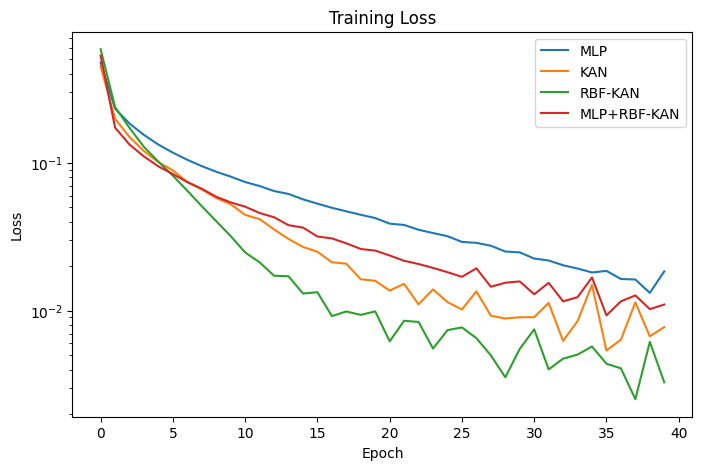

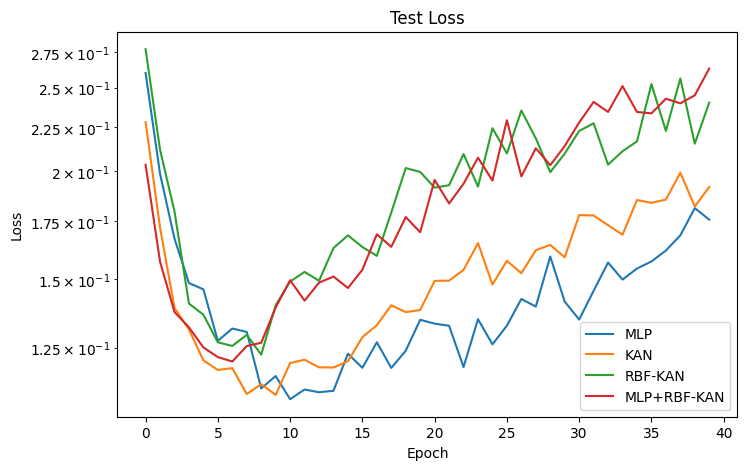

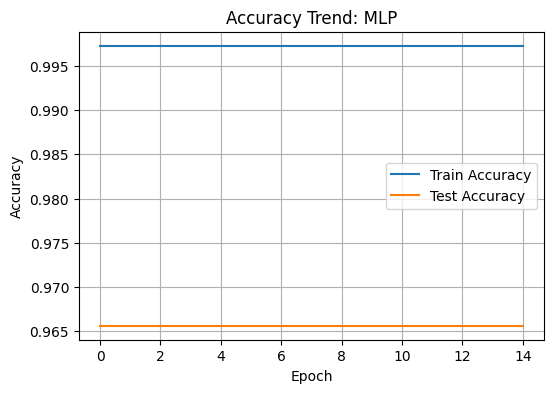

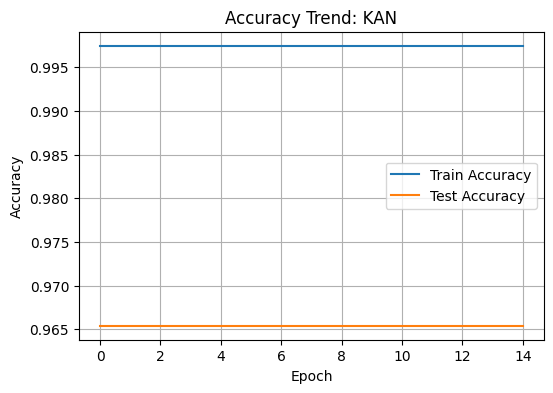

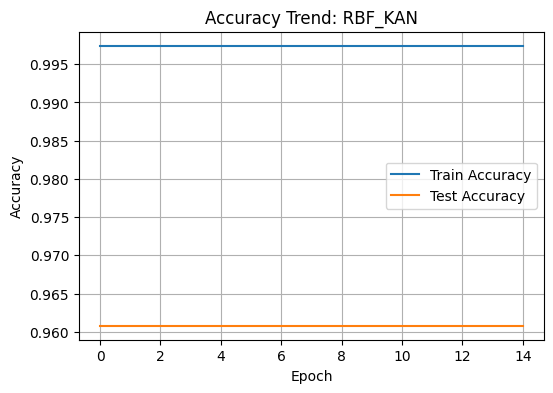

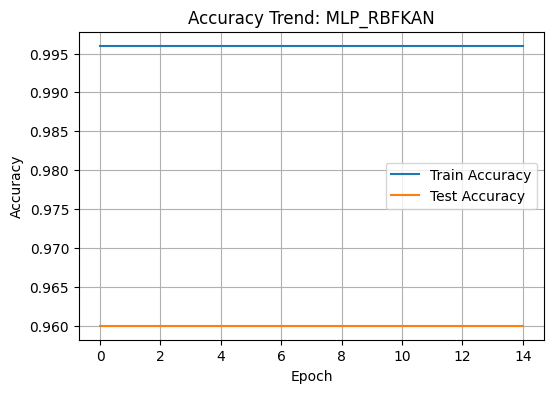

In [5]:
plot_losses(train_losses_dict, "Training Loss")
plot_losses(test_losses_dict, "Test Loss")

for name, model in models.items():
    plot_accuracy_trend(model, train_loader, test_loader, epochs=15, device=device)

In [6]:
print(f"Number of paramters [MLP]: {n_parameters(mlp)}")
print(f"Number of paramters [KAN]: {n_parameters(kan)}")
print(f"Number of paramters [RBF-KAN]: {n_parameters(rbf_kan)}")
print(f"Number of paramters [MLP with RBF-KAN]: {n_parameters(mlp_rbf)}")

Number of paramters [MLP]: 26506
Number of paramters [KAN]: 317184
Number of paramters [RBF-KAN]: 211578
Number of paramters [MLP with RBF-KAN]: 27178


In [7]:
print(metrics_dict)

{'MLP': {'accuracy': 0.9656, 'f1': 0.9655676234222774, 'precision': 0.9656329542195059, 'recall': 0.9656, 'conf_matrix': array([[ 966,    0,    0,    0,    2,    3,    6,    1,    1,    1],
       [   0, 1123,    5,    0,    1,    2,    1,    1,    2,    0],
       [   4,    6, 1001,    9,    2,    0,    0,    6,    4,    0],
       [   1,    0,    6,  972,    3,    5,    0,    9,    3,   11],
       [   0,    0,    4,    0,  949,    2,   10,    4,    2,   11],
       [   4,    0,    0,   19,    1,  848,    6,    2,    6,    6],
       [   6,    3,    4,    1,    3,    7,  929,    0,    5,    0],
       [   1,    8,   11,    4,    4,    0,    0,  992,    1,    7],
       [  11,    2,    3,   16,    7,    6,    2,    6,  913,    8],
       [   4,    1,    0,    6,   18,    7,    0,    6,    4,  963]])}, 'KAN': {'accuracy': 0.9654, 'f1': 0.9653668415653678, 'precision': 0.9654967802097338, 'recall': 0.9654, 'conf_matrix': array([[ 970,    0,    1,    1,    0,    3,    1,    2,    2,    0


MLP Confusion Matrix:


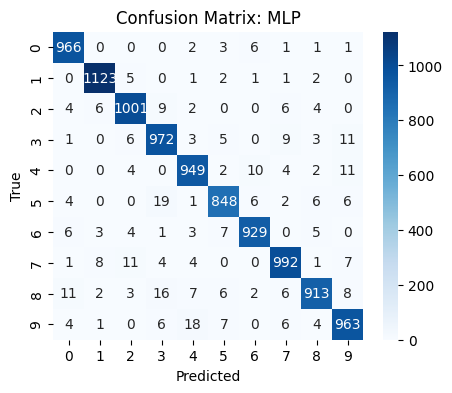


KAN Confusion Matrix:


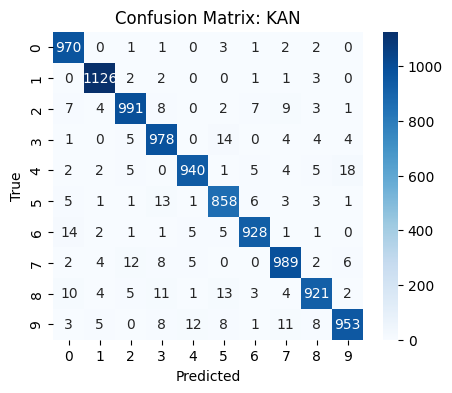


RBF-KAN Confusion Matrix:


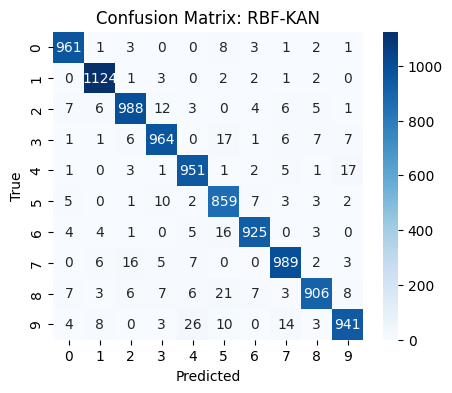


MLP+RBF-KAN Confusion Matrix:


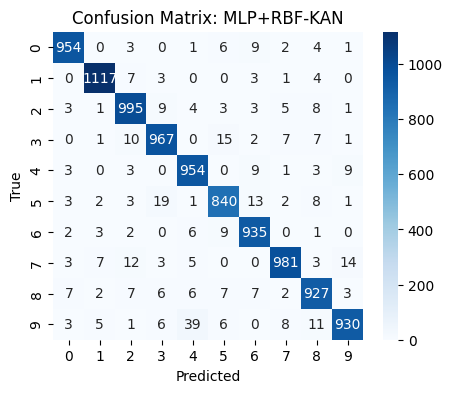

In [8]:
mnist_classes = [str(i) for i in range(10)]

for name, metrics in metrics_dict.items():
    print(f"\n{name} Confusion Matrix:")
    plot_confusion_matrix(metrics["conf_matrix"], classes=mnist_classes, model_name=name)

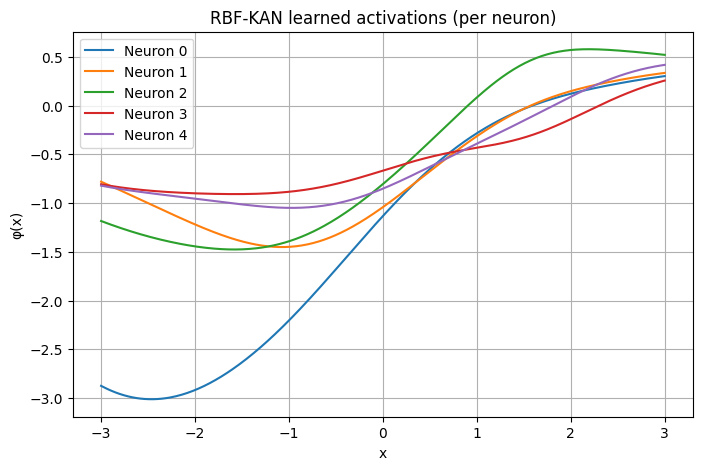

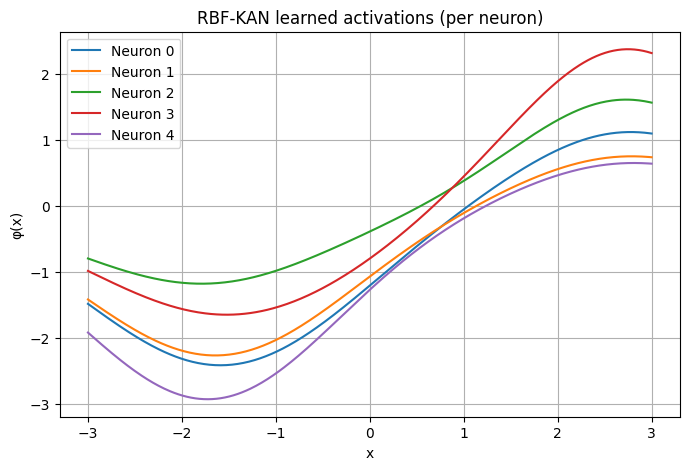

In [9]:
plot_rbf_neurons(mlp_rbf.act1)
plot_rbf_neurons(mlp_rbf.act2)

## Model Comparison: MNIST


=== Running seed 2 ===


Training Progress: 100%|██████████| 20/20 [01:29<00:00,  4.46s/it, Tr_Loss=0.0096, Te_Loss=0.1644]



=== Running seed 235 ===


Training Progress: 100%|██████████| 20/20 [01:36<00:00,  4.82s/it, Tr_Loss=0.0108, Te_Loss=0.1519]



=== Running seed 32 ===


...


=== Running seed 54 ===


Training Progress: 100%|██████████| 20/20 [01:29<00:00,  4.47s/it, Tr_Loss=0.0112, Te_Loss=0.1674]



=== Running seed 6 ===


Training Progress: 100%|██████████| 20/20 [01:29<00:00,  4.47s/it, Tr_Loss=0.0093, Te_Loss=0.1567]



================ FINAL RESULTS (mean ± std) ================

MLP
  accuracy: 9.752000e-01 ± 7.51e-04
  precision: 9.753201e-01 ± 6.91e-04
  recall: 9.752000e-01 ± 7.51e-04
  f1: 9.752106e-01 ± 7.41e-04

KAN
  accuracy: 9.722800e-01 ± 1.77e-03
  precision: 9.724025e-01 ± 1.70e-03
  recall: 9.722800e-01 ± 1.77e-03
  f1: 9.722657e-01 ± 1.78e-03

RBF-KAN
  accuracy: 1.135000e-01 ± 0.00e+00
  precision: 1.288225e-02 ± 1.73e-18
  recall: 1.135000e-01 ± 0.00e+00
  f1: 2.313830e-02 ± 0.00e+00

MLP with RBF-KAN
  accuracy: 9.695400e-01 ± 1.08e-03
  precision: 9.696870e-01 ± 1.04e-03
  recall: 9.695400e-01 ± 1.08e-03
  f1: 9.695408e-01 ± 1.06e-03



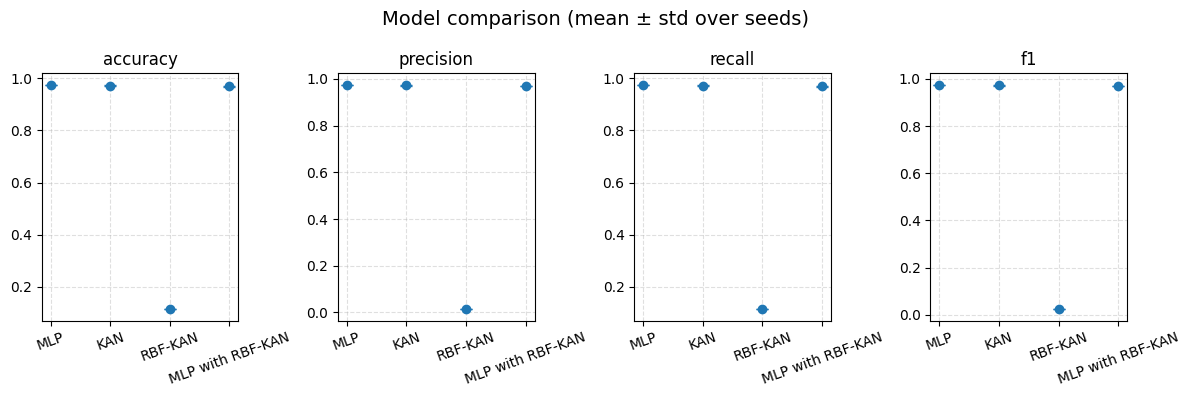

In [10]:
# Models definition
hidden_dim = 64
models = {
    "MLP": lambda: MLP(784, hidden_dim, 10),
    "KAN": lambda: KAN(
        width=[784, hidden_dim, hidden_dim, 10],
        num_knots=8,
        domain=(0, 1)
    ),
    "RBF-KAN": lambda: RBF_KAN(784, hidden_dim, 10, 8, (0, 1)),
    "MLP with RBF-KAN": lambda: MLP_RBFKAN(
        in_dim=784,
        hidden_dim=hidden_dim,
        out_dim=10,
        num_centers=8,
        domain=(-3, 3),
        shared_basis=True
    )
}

# Configurazione esperimento
cfg = ExperimentCfg(
    models=models,
    seeds=[2,235,32,54,6],
    epochs=20, 
    mlp_lr=1e-3,
    kan_lr=1e-3,
    batch_size=128,
    mlp_optimizer="adam",
    kan_optimizer="adam",
    device=device,
    domain=(-3,3),
    test_loader=test_loader,
    train_loader=train_loader,
)

runner = ExperimentalRunner(cfg)
runner.run_battery_experiments()
runner.plot_metrics_summary()